## Midterm Project: Berlin Rental Price Prediction

This is my midterm project for [ML Zoomcamp 2026](https://github.com/DataTalksClub/machine-learning-zoomcamp).

**Problem:** Predict the advertised nightly price of a short-term rental in Berlin using information about the listing, such as its neighbourhood, room type, and accommodation details. This could help compare advertised prices across similar listings.

**Dataset:** [Inside Airbnb — Berlin](https://insideairbnb.com/get-the-data/), summary `listings.csv` (26 June 2026 snapshot). Prices are *advertised nightly prices*, not actual booking transactions.

We will explore the data, train and evaluate regression models, and later deploy the selected model with FastAPI and Docker.

### Part 1: Data Loading and Exploration

In [2]:
# import used libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [3]:
# download the Berlin summary dataset (only once)
data_path = Path('data/listings.csv')
data_path.parent.mkdir(exist_ok=True)

url = 'https://data.insideairbnb.com/germany/be/berlin/2026-06-26/visualisations/listings.csv'

if not data_path.exists():
    pd.read_csv(url).to_csv(data_path, index=False)

# load the data
df = pd.read_csv(data_path)
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (12855, 19)


,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,3176,Fabulous Flat in great Location,3718.0,1.462506e+18,Britta,Pankow,Prenzlauer Berg Südwest,52.53574,13.41734,Entire home/apt,161.0,2.0,150,2025-08-09,0.72,1.0,342,1,First name and Last name: Nicolas Krotz <br/> ...
1,9991,Geourgeous flat - outstanding views,33852.0,1.462507e+18,Philipp,Pankow,Prenzlauer Berg Südwest,52.53269,13.41805,Entire home/apt,193.0,6.0,7,2020-01-04,0.05,1.0,261,0,03/Z/RA/003410-18
2,14325,Studio Apartment in Prenzlauer Berg,55531.0,1.462508e+18,Chris Und Oliver,Pankow,Prenzlauer Berg Nordwest,52.54624,13.40575,Entire home/apt,NaN,180.0,26,2023-11-30,0.13,2.0,211,0,NaN
3,17904,Beautiful Kreuzberg studio - 3 months minimum,68997.0,1.462508e+18,Matthias,Friedrichshain-Kreuzberg,südliche Luisenstadt,52.49626,13.42239,Entire home/apt,11.0,93.0,298,2026-05-31,1.49,1.0,184,2,NaN
4,20858,Designer Loft in Berlin Mitte,71331.0,1.462508e+18,Marc,Pankow,Prenzlauer Berg Südwest,52.53711,13.40888,Entire home/apt,373.0,3.0,145,2026-05-29,0.87,1.0,241,6,03/Z/RA/009767-24


In [4]:
# inspect columns, data types, and missing values
print(df.dtypes)
print('Missing values:')
print(df.isnull().sum())

# check the target column
print('Price examples:')
print(df['price'].head())

id                                  int64
name                                  str
host_id                           float64
host_profile_id                   float64
host_name                             str
neighbourhood_group                   str
neighbourhood                         str
latitude                          float64
longitude                         float64
room_type                             str
price                             float64
minimum_nights                    float64
number_of_reviews                   int64
last_review                           str
reviews_per_month                 float64
calculated_host_listings_count    float64
availability_365                    int64
number_of_reviews_ltm               int64
license                               str
dtype: object
Missing values:
id                                   0
name                                 0
host_id                             79
host_profile_id                     99
host_name       

### Part 2: Data Cleaning and Exploratory Data Analysis

We first remove listings without a valid nightly price. Then we examine the price distribution and compare prices across room types and neighbourhoods.

In [5]:
# remove listings with missing or invalid prices
df_clean = df.dropna(subset=['price']).copy()
df_clean = df_clean[df_clean['price'] > 0].copy()

print('Original shape:', df.shape)
print('Cleaned shape:', df_clean.shape)

# inspect the target distribution
df_clean['price'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

Original shape: (12855, 19)
Cleaned shape: (8515, 19)


count     8515.000000
mean       160.594950
std        204.185621
min          3.000000
25%         73.000000
50%        131.000000
75%        207.000000
90%        308.000000
95%        385.000000
99%        631.860000
max      10025.000000
Name: price, dtype: float64

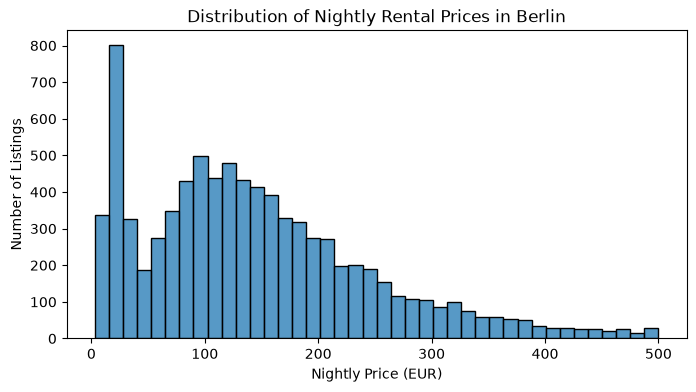

,count,median,mean
room_type,,,
Entire home/apt,6138,156.0,181.44
Hotel room,84,167.5,194.44
Private room,2209,92.0,105.35
Shared room,84,48.0,56.71


In [6]:
# visualize the typical price range (up to 500 EUR)
plt.figure(figsize=(8, 4))
sns.histplot(df_clean.loc[df_clean['price'] <= 500, 'price'], bins=40)
plt.title('Distribution of Nightly Rental Prices in Berlin')
plt.xlabel('Nightly Price (EUR)')
plt.ylabel('Number of Listings')
plt.show()

# compare prices across room types
df_clean.groupby('room_type')['price'].agg(
    ['count', 'median', 'mean']
).round(2)

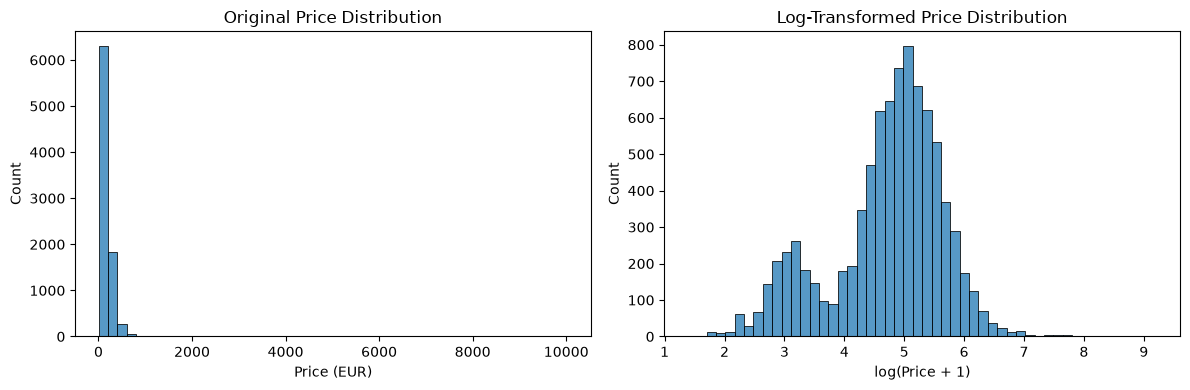

In [9]:
# compare original and log-transformed price distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_clean['price'], bins=50, ax=axes[0])
axes[0].set_title('Original Price Distribution')
axes[0].set_xlabel('Price (EUR)')

sns.histplot(np.log1p(df_clean['price']), bins=50, ax=axes[1])
axes[1].set_title('Log-Transformed Price Distribution')
axes[1].set_xlabel('log(Price + 1)')

plt.tight_layout()
plt.show()

The original price distribution is right-skewed, with most listings concentrated at lower prices and a long tail of expensive listings.

Applying `np.log1p()` compresses the higher values and makes the distribution less skewed. We therefore use log-transformed prices
as the target variable during model training.

Predictions will be converted back to euros using `np.expm1()` for evaluation and interpretation.

### Part 3: Feature Selection and Dataset Splitting

The price distribution contains a small number of extreme values. We focus on listings priced at €650 or less, covering approximately 99% of listings with known prices.

We select location, room type, minimum stay, reviews, and availability as predictors. The data is split into training (60%), validation
(20%), and test (20%) sets.

In [7]:
# limit extreme prices
df_model = df_clean[df_clean['price'] <= 650].copy()

# select relevant features
features = [
    'neighbourhood_group',
    'room_type',
    'latitude',
    'longitude',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'availability_365'
]

# keep features and target
df_model = df_model[features + ['price']]

# fill missing numeric feature values
df_model = df_model.fillna(0)

print('Modelling dataset:', df_model.shape)
print('Missing values:', df_model.isnull().sum().sum())

Modelling dataset: (8436, 9)
Missing values: 0


In [10]:
# standardize categorical values (lowercase, replace spaces with underscores)
categorical = ['neighbourhood_group', 'room_type']

for col in categorical:
    df_model[col] = df_model[col].str.lower().str.replace(' ', '_')

df_model.head()

,neighbourhood_group,room_type,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,availability_365,price
0,pankow,entire_home/apt,52.53574,13.41734,2.0,150,0.72,342,161.0
1,pankow,entire_home/apt,52.53269,13.41805,6.0,7,0.05,261,193.0
3,friedrichshain-kreuzberg,entire_home/apt,52.49626,13.42239,93.0,298,1.49,184,11.0
4,pankow,entire_home/apt,52.53711,13.40888,3.0,145,0.87,241,373.0
5,mitte,entire_home/apt,52.53316,13.38693,93.0,182,0.98,183,17.0


In [11]:
# split the data into train (60%), validation (20%), and test (20%)
df_full_train, df_test = train_test_split(
    df_model, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

# reset indices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# get target variable (log transformation)
y_train = np.log1p(df_train.price.values)
y_val = np.log1p(df_val.price.values)
y_test = np.log1p(df_test.price.values)

# remove target to prevent data leakage
del df_train['price']
del df_val['price']
del df_test['price']

# check dataset sizes
print(f"Train, Val, Test: ({len(df_train)}, {len(df_val)}, {len(df_test)})")
print(f"y_train, y_val, y_test: ({len(y_train)}, {len(y_val)}, {len(y_test)})")

df_train.head(3)

Train, Val, Test: (5061, 1687, 1688)
y_train, y_val, y_test: (5061, 1687, 1688)


,neighbourhood_group,room_type,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,availability_365
0,neukölln,entire_home/apt,52.465973,13.434565,3.0,20,0.49,193
1,mitte,private_room,52.530180,13.401860,1.0,0,0.00,175
2,pankow,entire_home/apt,52.561190,13.472860,1.0,2,0.77,109


### Part 4: Feature Encoding

We use `DictVectorizer` to one-hot encode categorical variables while keeping numerical features unchanged.
The vectorizer is fitted only on the training data to avoid data leakage.

In [12]:
# convert dataframes to dictionaries
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')
test_dicts = df_test.to_dict(orient='records')

# fit on training data, transform validation and test data
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

print('Train:', X_train.shape)
print('Validation:', X_val.shape)
print('Test:', X_test.shape)

dv.get_feature_names_out()

Train: (5061, 22)
Validation: (1687, 22)
Test: (1688, 22)


array(['availability_365', 'latitude', 'longitude', 'minimum_nights',
       'neighbourhood_group=charlottenburg-wilm.',
       'neighbourhood_group=friedrichshain-kreuzberg',
       'neighbourhood_group=lichtenberg',
       'neighbourhood_group=marzahn_-_hellersdorf',
       'neighbourhood_group=mitte', 'neighbourhood_group=neukölln',
       'neighbourhood_group=pankow', 'neighbourhood_group=reinickendorf',
       'neighbourhood_group=spandau',
       'neighbourhood_group=steglitz_-_zehlendorf',
       'neighbourhood_group=tempelhof_-_schöneberg',
       'neighbourhood_group=treptow_-_köpenick', 'number_of_reviews',
       'reviews_per_month', 'room_type=entire_home/apt',
       'room_type=hotel_room', 'room_type=private_room',
       'room_type=shared_room'], dtype=object)

### Part 5: Model Training and Evaluation

We start with Linear Regression as a baseline model.

The model predicts log-transformed prices. We evaluate its performance using RMSE on the validation dataset, both in log space and in euros.

We will then compare it with tree-based models.

In [13]:
# train baseline model
lr = LinearRegression()
lr.fit(X_train, y_train)

# predict log-prices on validation data
y_pred = lr.predict(X_val)

# calculate RMSE in log space
rmse_log = np.sqrt(mean_squared_error(y_val, y_pred))

# convert predictions and actual values back to euros
y_pred_eur = np.expm1(y_pred)
y_val_eur = np.expm1(y_val)

# calculate errors in euros
rmse_eur = np.sqrt(mean_squared_error(y_val_eur, y_pred_eur))
mae_eur = mean_absolute_error(y_val_eur, y_pred_eur)

print(f'Linear Regression - RMSE (log): {rmse_log:.4f}')
print(f'Linear Regression - RMSE (EUR): {rmse_eur:.2f}')
print(f'Linear Regression - MAE (EUR): {mae_eur:.2f}')

Linear Regression - RMSE (log): 0.4680
Linear Regression - RMSE (EUR): 85.23
Linear Regression - MAE (EUR): 52.31


### Part 6: Decision Tree Regression

We train a Decision Tree Regressor and tune its maximum depth.

Different tree depths are evaluated on the validation dataset using RMSE. This helps us find a suitable balance between underfitting and overfitting.

In [14]:
# test different maximum tree depths
for depth in [3, 5, 7, 10, 15, 20]:
    dt = DecisionTreeRegressor(max_depth=depth, random_state=1)
    dt.fit(X_train, y_train)

    y_pred = dt.predict(X_val)

    rmse_log = np.sqrt(mean_squared_error(y_val, y_pred))
    rmse_eur = np.sqrt(
        mean_squared_error(np.expm1(y_val), np.expm1(y_pred))
    )

    print(f'Depth {depth:2d}: RMSE (log) = {rmse_log:.4f}, RMSE (EUR) = {rmse_eur:.2f}')

Depth  3: RMSE (log) = 0.4648, RMSE (EUR) = 87.62
Depth  5: RMSE (log) = 0.4541, RMSE (EUR) = 86.70
Depth  7: RMSE (log) = 0.4562, RMSE (EUR) = 85.64
Depth 10: RMSE (log) = 0.4591, RMSE (EUR) = 85.37
Depth 15: RMSE (log) = 0.5081, RMSE (EUR) = 93.65
Depth 20: RMSE (log) = 0.5466, RMSE (EUR) = 104.57


### Part 7: Random Forest Regression

Random Forest combines predictions from multiple decision trees.

We tune `max_depth` and `min_samples_leaf` to compare different model complexities and evaluate performance on the validation set.

We use RMSE in euros as the primary metric for model selection.

In [15]:
# test different random forest configurations
for depth in [5, 10, 15]:
    for leaf in [1, 5]:
        rf = RandomForestRegressor(
            n_estimators=100,
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=1,
            n_jobs=-1
        )

        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_val)

        rmse_log = np.sqrt(mean_squared_error(y_val, y_pred))
        rmse_eur = np.sqrt(
            mean_squared_error(np.expm1(y_val), np.expm1(y_pred))
        )

        print(
            f'Depth {depth:2d}, Leaf {leaf}: '
            f'RMSE (log) = {rmse_log:.4f}, '
            f'RMSE (EUR) = {rmse_eur:.2f}'
        )

Depth  5, Leaf 1: RMSE (log) = 0.4402, RMSE (EUR) = 85.04
Depth  5, Leaf 5: RMSE (log) = 0.4398, RMSE (EUR) = 85.02
Depth 10, Leaf 1: RMSE (log) = 0.4209, RMSE (EUR) = 80.89
Depth 10, Leaf 5: RMSE (log) = 0.4195, RMSE (EUR) = 80.94
Depth 15, Leaf 1: RMSE (log) = 0.4178, RMSE (EUR) = 78.88
Depth 15, Leaf 5: RMSE (log) = 0.4151, RMSE (EUR) = 79.14



### Model Comparison and Selection

We trained and evaluated three regression models: Linear Regression, Decision Tree, and Random Forest. For the tree-based models, we also experimented with different hyperparameters to improve their performance.

The following table summarizes the validation results:

| Model | Hyperparameters | RMSE (log) | RMSE (EUR) |
|---|---|---:|---:|
| Linear Regression | Default | 0.4680 | 85.23 |
| Decision Tree | max_depth=5 | 0.4541 | 86.70 |
| Decision Tree | max_depth=10 | 0.4591 | 85.37 |
| Random Forest | max_depth=10, min_samples_leaf=1 | 0.4209 | 80.89 |
| Random Forest | max_depth=15, min_samples_leaf=1 | 0.4178 | **78.88** |
| Random Forest | max_depth=15, min_samples_leaf=5 | **0.4151** | 79.14 |

**Observations:**

- Linear Regression provides a reasonable baseline, with an RMSE of €85.23.
- Decision Tree performance depends on tree depth. Very deep trees show signs of overfitting, resulting in higher validation errors.
- Random Forest consistently outperforms the other models, benefiting from combining multiple decision trees.
- The lowest RMSE in log space (0.4151) is achieved with `max_depth=15` and `min_samples_leaf=5`.
- The lowest RMSE in euros (€78.88) is achieved with `max_depth=15` and `min_samples_leaf=1`.

**Selected Model: Random Forest Regressor**

We select Random Forest with `n_estimators=100`, `max_depth=15`, and `min_samples_leaf=1`, using RMSE in euros as our primary evaluation metric.

This model reduces validation RMSE by approximately **7.5%** compared with Linear Regression.

Next, we examine feature importance to better understand which listing characteristics contribute most to the predictions.

### Part 8: Feature Importance

We examine feature importance using the best-performing Random Forest model.

Feature importance indicates which predictors contribute most to the model's decisions. It helps us understand the role of location, room type, availability, and review-related features in predicting prices.

In [16]:
# train the best random forest configuration
rf_best = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=1,
    random_state=1,
    n_jobs=-1
)

rf_best.fit(X_train, y_train)

# calculate feature importance
feature_importance = pd.DataFrame({
    'feature': dv.get_feature_names_out(),
    'importance': rf_best.feature_importances_
})

feature_importance = feature_importance.sort_values(
    'importance', ascending=False
)

feature_importance.head(10)

,feature,importance
3,minimum_nights,0.709176
18,room_type=entire_home/apt,0.085097
1,latitude,0.043182
2,longitude,0.042483
0,availability_365,0.038807
17,reviews_per_month,0.027616
16,number_of_reviews,0.023907
8,neighbourhood_group=mitte,0.007146
21,room_type=shared_room,0.006052
20,room_type=private_room,0.005280


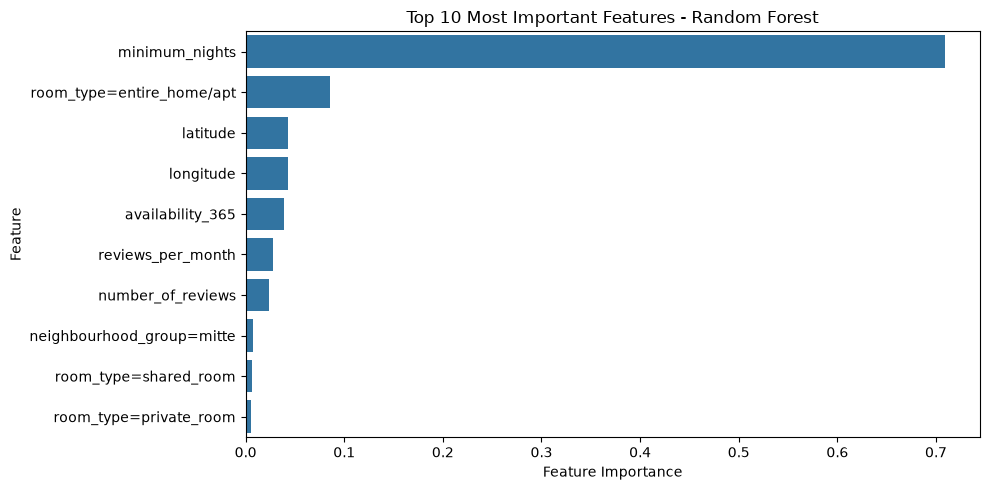

In [17]:
# plot the 10 most important features
plt.figure(figsize=(10, 5))

sns.barplot(
    data=feature_importance.head(10),
    x='importance',
    y='feature'
)

plt.title('Top 10 Most Important Features - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()


**Feature Importance Observations**

- `minimum_nights` is the most influential feature in the Random Forest, accounting for approximately 70.9% of the model's impurity-based importance.
- `room_type=entire_home/apt` is the second most important feature (8.5%), suggesting that accommodation type is useful for price prediction.
- Geographic features (`latitude` and `longitude`) also contribute to the model.
- Availability and review-related features have smaller individual importance scores.

The unusually high importance of `minimum_nights` may reflect patterns in the dataset and should be investigated further. Feature importance does not establish causation.


### Part 9: Final Model Training and Test Evaluation

After comparing the models on the validation dataset, we retrain the selected Random Forest using the combined training and validation data.

We then evaluate its performance on the previously unseen test set to estimate how well it generalizes to new listings.

In [18]:
# prepare combined training and validation data
y_full_train = np.log1p(df_full_train['price'].values)

df_full_train_features = df_full_train.drop(columns=['price'])

# fit a new vectorizer on all development data
dv_final = DictVectorizer(sparse=False)

X_full_train = dv_final.fit_transform(
    df_full_train_features.to_dict(orient='records')
)

X_test_final = dv_final.transform(
    df_test.to_dict(orient='records')
)

# train the selected model
model_final = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=1,
    random_state=1,
    n_jobs=-1
)

model_final.fit(X_full_train, y_full_train)

# evaluate on the test dataset
y_pred_test = model_final.predict(X_test_final)

rmse_log_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

y_pred_test_eur = np.expm1(y_pred_test)
y_test_eur = np.expm1(y_test)

rmse_eur_test = np.sqrt(
    mean_squared_error(y_test_eur, y_pred_test_eur)
)
mae_eur_test = mean_absolute_error(y_test_eur, y_pred_test_eur)

print(f'Final Test RMSE (log): {rmse_log_test:.4f}')
print(f'Final Test RMSE (EUR): {rmse_eur_test:.2f}')
print(f'Final Test MAE (EUR): {mae_eur_test:.2f}')

Final Test RMSE (log): 0.4083
Final Test RMSE (EUR): 76.17
Final Test MAE (EUR): 48.30


### Part 10: Model Export

We save the final trained Random Forest and its fitted DictVectorizer using Python's `pickle` module.

Both objects are required for deployment because incoming listing data must undergo the same feature encoding used during training.

The exported model will be loaded by our prediction API.

In [19]:
import pickle

# save the final vectorizer and model
output_file = 'model.bin'

with open(output_file, 'wb') as f_out:
    pickle.dump((dv_final, model_final), f_out)

print(f'Model saved to {output_file}')

Model saved to model.bin


In [20]:
# load the saved model to verify it
with open('model.bin', 'rb') as f_in:
    dv_loaded, model_loaded = pickle.load(f_in)

# test one prediction
sample = df_test.iloc[0].to_dict()

X_sample = dv_loaded.transform([sample])
prediction = np.expm1(model_loaded.predict(X_sample)[0])

print(f'Predicted price: €{prediction:.2f}')
print(f'Actual price: €{np.expm1(y_test[0]):.2f}')

Predicted price: €28.16
Actual price: €19.00
